<h3 style="text-align: center;"><b>Лабораторная работа №3</b></h3>

<h3 style="text-align: center;"><b>Транскрипция / G2P</b></h3>

# Построение фонетической транскрипции для RUSLAN

В этой работе я продолжаю подготовку данных для синтеза речи после первых двух лабораторных

Теперь задача состоит в том, чтобы для каждого слова получить последовательность фонем. Под G2P здесь я простое преобразование: **написанное слово -> фонемы**

Сначала подготовлю разметку из MFA, затем посмотрю на сами фонемы и соберу простой baseline. После этого отдельно улучшу слова, которых нет ни в одном словаре, и проверю результат по PER

## План работы

Буду двигаться последовательно:

1. Проверю окружение и пути к данным
2. Подготовлю `tokens_phones.csv`, `tokens_phones_sil.csv` и `lexicon.csv`
3. Посмотрю, какие фонемы встречаются в корпусе и как часто
4. Проверю длительности и редкие фонемы
5. Сравню получившийся набор с `phones_mfa.txt`
6. Посмотрю OOV-слова и варианты произношения
7. Соберу простой G2P baseline
8. Поэтапно улучшу обработку residual OOV
9. Сравню варианты по `test PER` и `OOV PER`
10. Разберу основные ошибки и слова с несколькими произношениями
11. Выберу финальный вариант


## Окружение

#### Импорты

In [2]:
%matplotlib inline

import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from praatio import textgrid


LAB_DIR = Path.cwd()
DATA_DIR = LAB_DIR / "data"
OUT_DIR = LAB_DIR / "outputs"

ALIGN_DIR = (LAB_DIR / "../../data/RUSLAN_align_v2").resolve()

TOKENS_PATH = DATA_DIR / "tokens_phones.csv"
TOKENS_SIL_PATH = DATA_DIR / "tokens_phones_sil.csv"
LEXICON_PATH = DATA_DIR / "lexicon.csv"
MFA_DICT_PATH = DATA_DIR / "russian_mfa.dict"

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("LAB_DIR:", LAB_DIR.resolve())
print("DATA_DIR:", DATA_DIR.resolve())
print("ALIGN_DIR:", ALIGN_DIR)

LAB_DIR: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab3_g2p
DATA_DIR: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab3_g2p\data
ALIGN_DIR: D:\МАГА\2 курс\Синтез речи\LABS\data\RUSLAN_align_v2


In [3]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 150

## Пути к данным

Основные входные данные:

- `../../data/RUSLAN_align_v2/` - TextGrid-файлы после MFA
- `../../data/metadata_RUSLAN_22200_normalized.csv` - нормализованные тексты из первой лабораторной
- `data/russian_mfa.dict` - словарь произношений Russian MFA
- `common/phones_mfa.txt` - список фонем, который используется в работе

В процессе работы будут созданы:

- `data/tokens_phones.csv`
- `data/tokens_phones_sil.csv`
- `data/lexicon.csv`
- `data/metadata_phones_gt.csv`
- `data/metadata_phones.csv`

Основной код находится в файлах `prepare_lexicon.py` и `g2p.py`

# Часть 1. Подготовка фонетических данных

Для этой лабораторной использую `.TextGrid`, которые уже были получены после MFA

В каждом файле есть два нужных мне уровня:

- `words` - интервалы слов
- `phones` - интервалы фонем

Скрипт `prepare_lexicon.py` сопоставляет их и создаёт:

- `tokens_phones.csv` - слова без пауз
- `tokens_phones_sil.csv` - те же данные, но с `<SIL>`
- `lexicon.csv` - словарь вариантов произношения только по `train`

Отдельно убираю предложения со `spn`. Я воспринимаю `spn` как случай, где нормальной фонемной транскрипции нет, поэтому такой пример целиком дальше не использую.

In [4]:
required_before_analysis = [
    TOKENS_PATH,
    TOKENS_SIL_PATH,
    LEXICON_PATH,
]

missing = [
    path
    for path in required_before_analysis
    if not path.exists()
]

if missing:
    print("Сначала нужно запустить:")
    print("python prepare_lexicon.py")
    print()
    print("Пока не найдены:")
    for path in missing:
        print(" -", path)
else:
    print("Основные файлы подготовлены.")

Основные файлы подготовлены.


## Посмотрим на получившиеся таблицы

In [6]:
tokens = pd.read_csv(
    TOKENS_PATH,
    sep="|",
    quoting=csv.QUOTE_NONE,
)

tokens_sil = pd.read_csv(
    TOKENS_SIL_PATH,
    sep="|",
    quoting=csv.QUOTE_NONE,
)

lexicon = pd.read_csv(
    LEXICON_PATH,
    sep="|",
    quoting=csv.QUOTE_NONE,
)

display(tokens.head(10))
display(tokens_sil.head(10))
display(lexicon.head(10))

,id,token_id,token,phones,set
0,000000_RUSLAN,0,с,s̪,test
1,000000_RUSLAN,1,тревожным,t̪ rʲ ɪ v o ʐ n̪ ɨ m,test
2,000000_RUSLAN,2,чувством,tɕ u s̪ t̪ v ə m,test
3,000000_RUSLAN,3,берусь,bʲ ɪ r u sʲ,test
4,000000_RUSLAN,4,я,j a,test
5,000000_RUSLAN,5,за,z̪ ə,test
6,000000_RUSLAN,6,перо,pʲ ɪ r o,test
7,000001_RUSLAN,0,кого,k ɐ v o,train
8,000001_RUSLAN,1,интересуют,ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪,train
9,000001_RUSLAN,2,признания,p rʲ ɪ z̪ n̪ a ɲ e,train


,id,token_id,token,phones,set
0,000000_RUSLAN,0,с,s̪,test
1,000000_RUSLAN,1,тревожным,t̪ rʲ ɪ v o ʐ n̪ ɨ m,test
2,000000_RUSLAN,2,чувством,tɕ u s̪ t̪ v ə m,test
3,000000_RUSLAN,3,берусь,bʲ ɪ r u sʲ,test
4,000000_RUSLAN,4,я,j a,test
5,000000_RUSLAN,5,за,z̪ ə,test
6,000000_RUSLAN,6,перо,pʲ ɪ r o,test
7,000000_RUSLAN,7,<SIL>,<SIL>,test
8,000001_RUSLAN,0,кого,k ɐ v o,train
9,000001_RUSLAN,1,<SIL>,<SIL>,train


,word,phones,count
0,а,ɐ,1385
1,а,a,32
2,а,ə,6
3,абажуром,ɐ b ɐ ʐ u r ə m,4
4,абанамат,ɐ b ə n̪ ɐ m a t̪,5
5,абдулаев,ɐ b d̪ u ɫ ə j ɪ f,1
6,абдуллаев,ɐ b d̪ ʊ ɫ a j ɪ f,1
7,абзаца,ɐ b z̪ a t̪s̪ ə,1
8,абитуриентов,ɐ bʲ ɪ t̪ ʊ rʲ ɪ j e n̪ t̪ ə f,1
9,абонента,ɐ b ɐ ɲ e n̪ t̪ ə,1


Формат `tokens_phones.csv`:

- `id` - номер предложения
- `token_id` - номер токена внутри предложения
- `token` - слово
- `phones` - фонемы этого слова
- `set` - `train` или `test`

In [7]:
data_summary = pd.DataFrame(
    {
        "Таблица": [
            "tokens_phones",
            "tokens_phones_sil",
            "lexicon",
        ],
        "Строк": [
            len(tokens),
            len(tokens_sil),
            len(lexicon),
        ],
    }
)

data_summary

,Таблица,Строк
0,tokens_phones,219600
1,tokens_phones_sil,272240
2,lexicon,39165


In [8]:
split_summary = (
    tokens
    .groupby("set")
    .agg(
        tokens=("token", "size"),
        utterances=("id", "nunique"),
    )
)

split_summary

,tokens,utterances
set,,
test,44357,3980
train,175243,15715


## Проверка пауз

В таблице с паузами токен `<SIL>` должен остаться отдельным элементом

In [9]:
sil_count = (tokens_sil["token"] == "<SIL>").sum()

print("Количество <SIL>:", sil_count)

display(
    tokens_sil[
        tokens_sil["token"] == "<SIL>"
    ].head(10)
)

Количество <SIL>: 52640


,id,token_id,token,phones,set
7,000000_RUSLAN,7,<SIL>,<SIL>,test
9,000001_RUSLAN,1,<SIL>,<SIL>,train
14,000001_RUSLAN,6,<SIL>,<SIL>,train
19,000002_RUSLAN,4,<SIL>,<SIL>,train
21,000002_RUSLAN,6,<SIL>,<SIL>,train
32,000004_RUSLAN,3,<SIL>,<SIL>,train
43,000006_RUSLAN,5,<SIL>,<SIL>,train
47,000006_RUSLAN,9,<SIL>,<SIL>,train
52,000007_RUSLAN,2,<SIL>,<SIL>,train
64,000008_RUSLAN,8,<SIL>,<SIL>,train


### Вывод

После фильтрации осталось **19 695 предложений** и **219 600 слов** без пауз.

Получены две версии данных:

1. `tokens_phones.csv` - без пауз, для обучения и проверки G2P
2. `tokens_phones_sil.csv` - с `<SIL>`, для подготовки данных следующей лабораторной

В `tokens_phones_sil.csv` получилось **52640** токенов `<SIL>`

`lexicon.csv` строится только по `train`, поэтому произношения из `test` в него не попадают. В нём **38 520 уникальных слов**; строк немного больше, потому что у части слов есть несколько вариантов произношения

# Часть 2. Инвентарь и частоты фонем

Сначала просто посчитаем, сколько раз встретилась каждая фонема

## Обозначения фонем

В корпусе встретилось **55 речевых фонем**. Обозначения основаны на IPA - международной системе записи звуков

Например:

- `ʲ` показывает мягкость согласной
- `̪` показывает более переднее положение языка
- отдельными символами записаны разные варианты гласных

В `phones_mfa.txt` находится 56 элементов: 55 речевых фонем и специальный токен `<SIL>`

In [10]:
all_phones = []

for phones in tokens["phones"].fillna(""):
    all_phones.extend(str(phones).split())

phone_counts = pd.Series(
    Counter(all_phones),
    name="count",
).sort_values(ascending=False)

print("Уникальных фонем:", len(phone_counts))

phone_counts.to_frame().head(20)

Уникальных фонем: 55


,count
ɪ,100451
ə,93920
ɐ,65403
a,55347
t̪,54282
j,48376
n̪,48375
e,43411
s̪,41207
r,40029


#### Самые частые фонемы

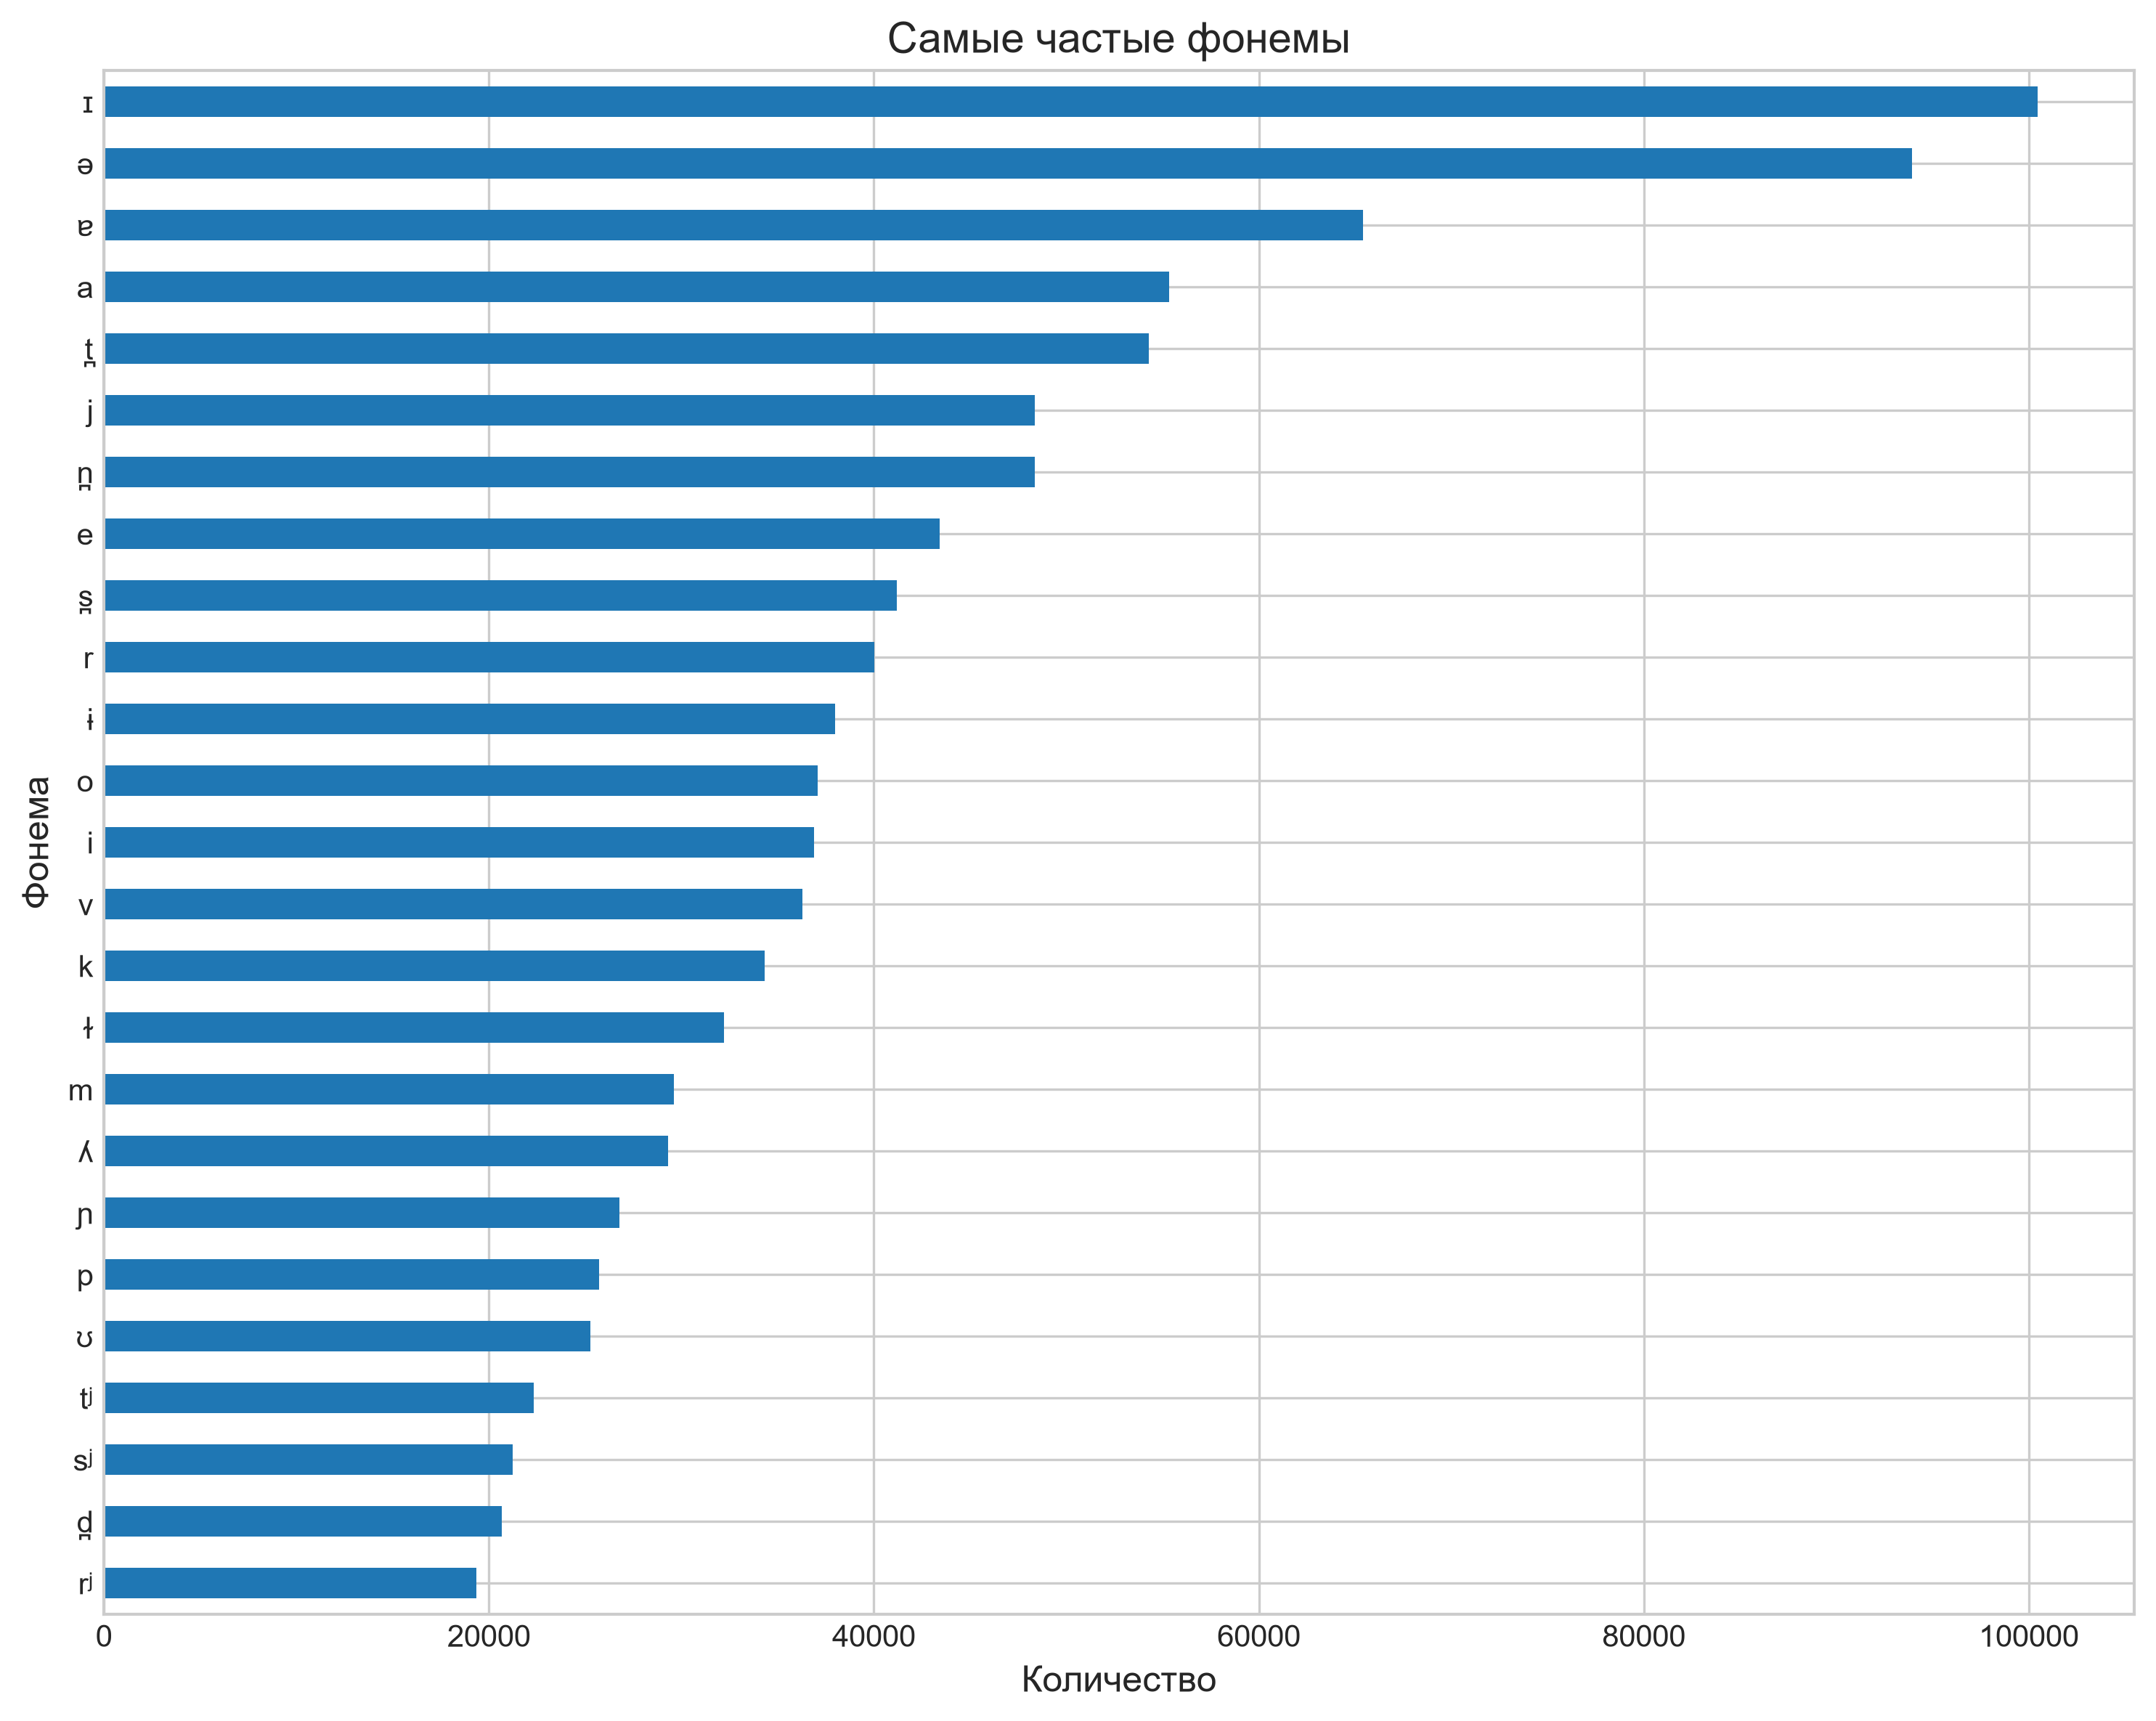

In [11]:
top_phones = phone_counts.head(25).sort_values()

plt.figure(figsize=(10, 8))
top_phones.plot(kind="barh")
plt.title("Самые частые фонемы")
plt.xlabel("Количество")
plt.ylabel("Фонема")
plt.tight_layout()
plt.show()

#### Самые редкие фонемы

In [12]:
rare_phones = phone_counts.sort_values().head(20)

rare_phones.to_frame()

,count
d̪z̪,1
ʑ,18
ɣ,18
dʐ,228
tʂ,279
ç,492
ɵ,949
fʲ,1868
ʉ,2400
æ,3421


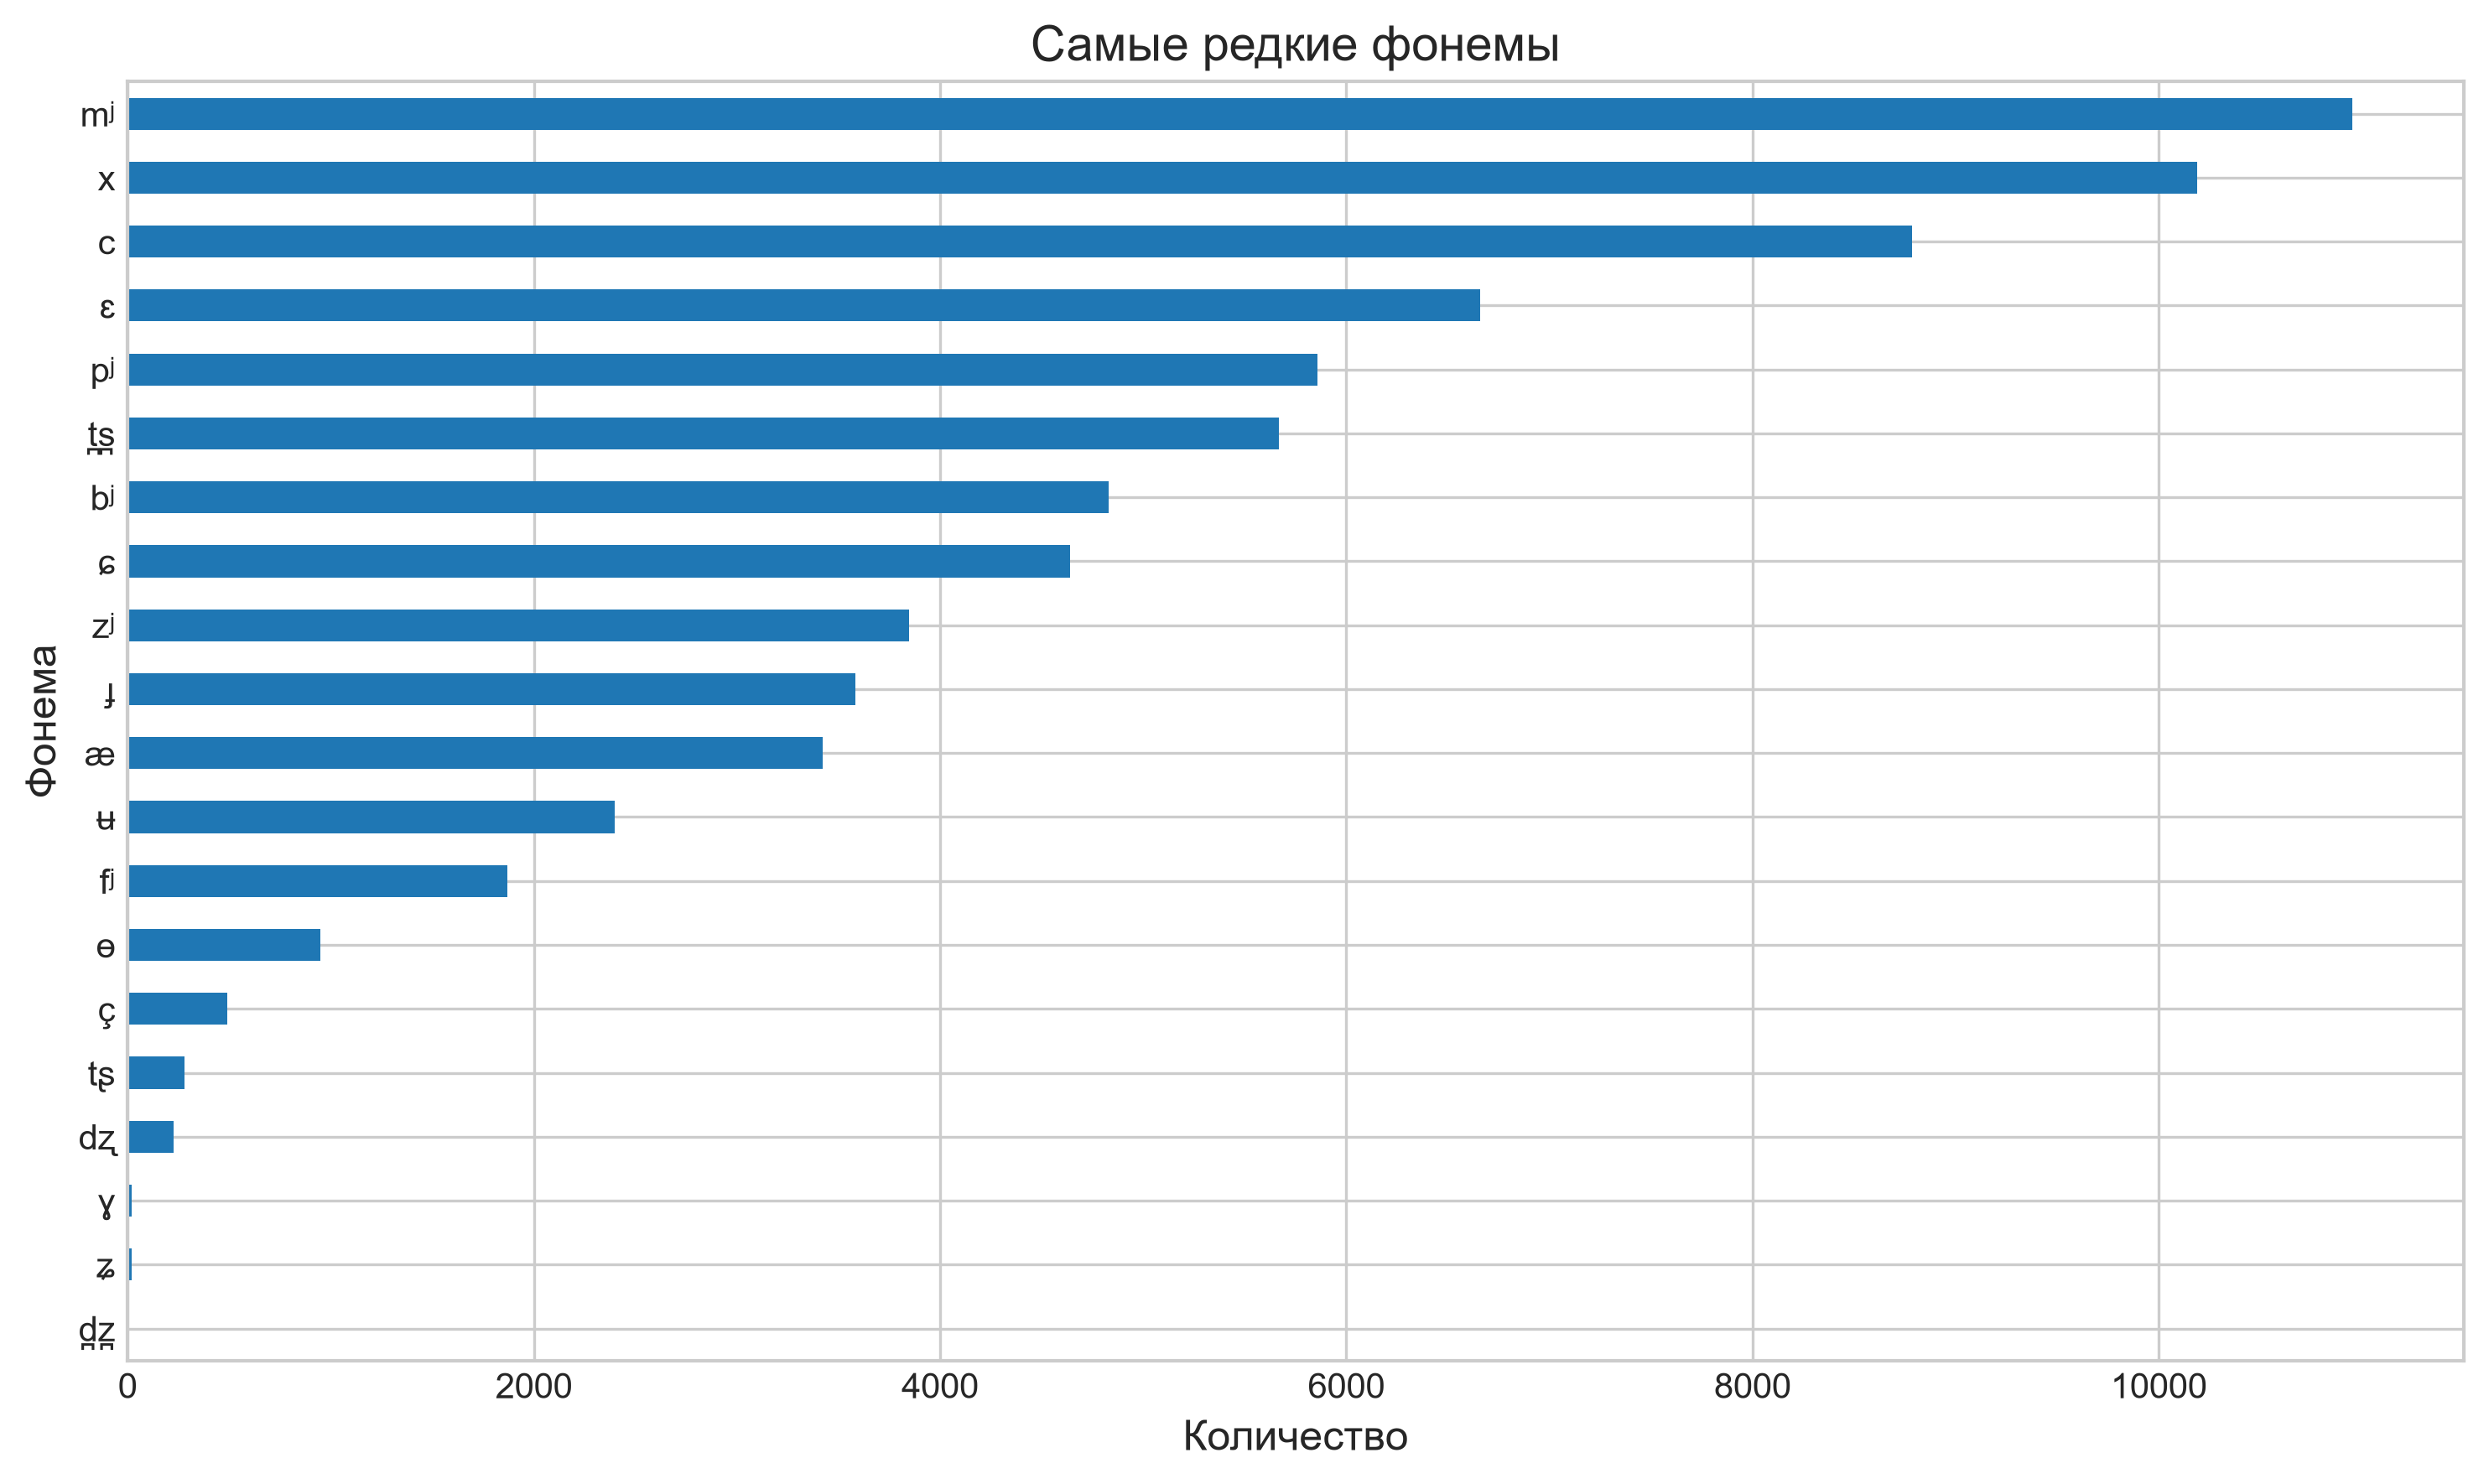

In [13]:
plt.figure(figsize=(10, 6))
rare_phones.plot(kind="barh")
plt.title("Самые редкие фонемы")
plt.xlabel("Количество")
plt.ylabel("Фонема")
plt.tight_layout()
plt.show()

### Вывод

Большая часть фонем встречается много раз, но есть несколько очень редких:

- `d̪z̪` - 1 раз
- `ʑ` - 18 раз
- `ɣ` - 18 раз

Удалять их только из-за маленькой частоты не буду. 
Все эти фонемы входят в целевой `phones_mfa.txt`, поэтому они остаются

Редкие фонемы могут быть связаны с редкими словами или особенностями выравнивания, поэтому их лучше учитывать отдельно при анализе ошибок

## Проверка необычных токенов

После нормализации в `tokens_phones.csv` не осталось токенов с цифрами, дефисами или апострофами

При этом словесные формы сокращений встречаются. Например:

- `кэгэбэ` встречается 43 раза; основной вариант - `k ɨ ɡ ɛ b ɛ`
- `цека` встречается 29 раз; основной вариант - `t̪s̪ ɨ k a`

То есть такие примеры после нормализации представлены обычными буквами и имеют фонетическое выравнивание

# Часть 3. Длительности фонем

В `tokens_phones.csv` времени уже нет, поэтому длительности возьмём прямо из уровня `phones` в `.TextGrid`

Длительность считаем просто: `конец интервала - начало интервала`

In [ ]:
def read_phone_durations(align_dir, kept_ids):
    rows = []

    paths = sorted(Path(align_dir).glob("*.TextGrid"))

    for path in paths:
        # Используем только предложения, которые остались после фильтрации
        if path.stem not in kept_ids:
            continue

        try:
            tg = textgrid.openTextgrid(
                str(path),
                includeEmptyIntervals=True,
            )
            phone_tier = tg.getTier("phones")
        except Exception:
            continue

        for entry in phone_tier.entries:
            phone = str(entry.label)

            if phone in {"", "spn"}:
                continue

            # В prepare_lexicon.py этот знак тоже убирается
            phone = phone.replace("ː", "")

            rows.append(
                {
                    "id": path.stem,
                    "phone": phone,
                    "duration": float(
                        entry.end - entry.start
                    ),
                }
            )

    return pd.DataFrame(rows)

In [15]:
kept_ids = set(tokens["id"])

phone_durations = read_phone_durations(
    ALIGN_DIR,
    kept_ids,
)

print("Интервалов фонем:", len(phone_durations))

phone_durations.head()

Интервалов фонем: 1239215


,id,phone,duration
0,000000_RUSLAN,s̪,0.11
1,000000_RUSLAN,t̪,0.07
2,000000_RUSLAN,rʲ,0.08
3,000000_RUSLAN,ɪ,0.01
4,000000_RUSLAN,v,0.09


In [16]:
duration_stats = (
    phone_durations
    .groupby("phone")["duration"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

duration_stats.head(20)

,count,mean,median,std
phone,,,,
ɪ,100451,0.017736,0.01,0.025606
ə,93920,0.039812,0.03,0.034624
ɐ,65403,0.064145,0.06,0.020947
a,55347,0.089003,0.09,0.035775
t̪,54282,0.078908,0.07,0.032052
j,48376,0.065547,0.05,0.039093
n̪,48375,0.068411,0.06,0.031550
e,43411,0.073731,0.07,0.034986
s̪,41207,0.101887,0.10,0.033362


#### Средняя длительность

Для графика беру фонемы, которые встретились хотя бы 20 раз

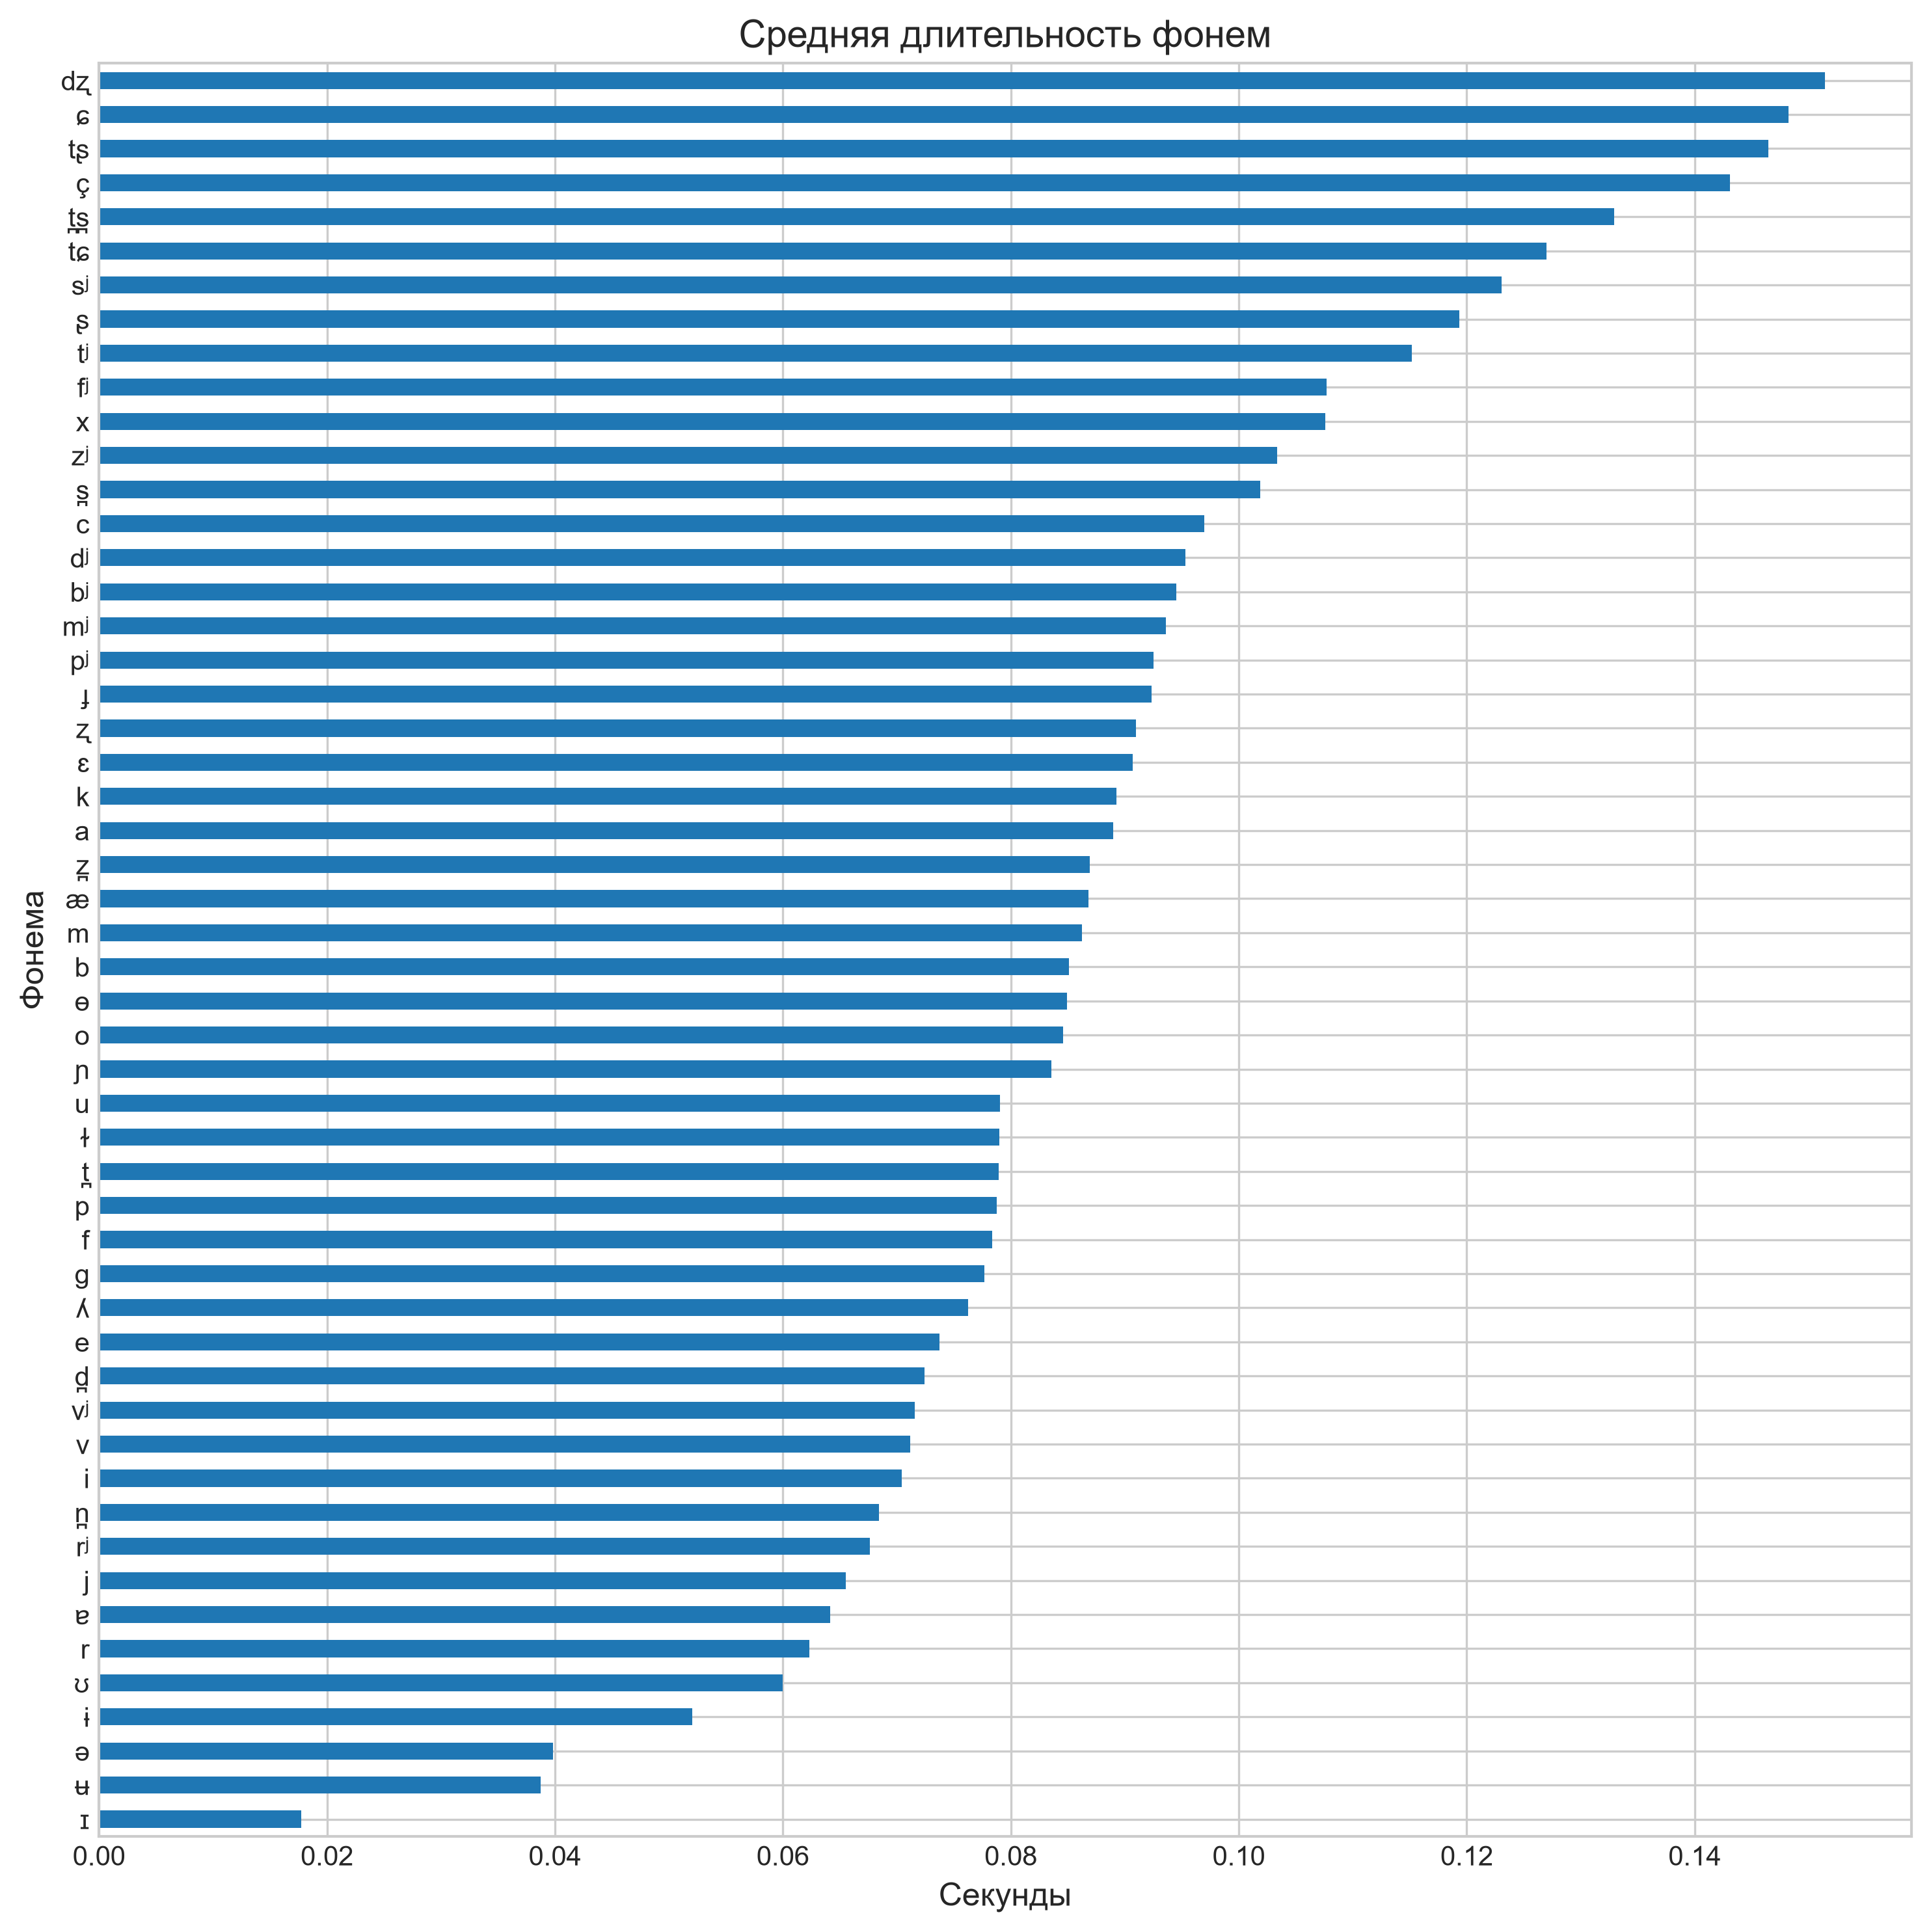

In [17]:
duration_plot = (
    duration_stats[
        duration_stats["count"] >= 20
    ]
    .sort_values("mean")
)

plt.figure(figsize=(10, 10))
duration_plot["mean"].plot(kind="barh")
plt.title("Средняя длительность фонем")
plt.xlabel("Секунды")
plt.ylabel("Фонема")
plt.tight_layout()
plt.show()

### Вывод

Разные фонемы имеют разную среднюю длительность, а одна и та же фонема может звучать немного дольше или короче в разных словах

Для G2P длительность напрямую не предсказывается

# Часть 4. Сравнение с `phones_mfa.txt`

По условию итоговый G2P должен использовать только фонемы из `phones_mfa.txt`

Проверим, есть ли в RUSLAN обозначения, которых нет в этом списке

In [18]:
phone_candidates = [
    LAB_DIR / "common/phones_mfa.txt",
    LAB_DIR / "configs/phones_mfa.txt",
]

phones_file = next(
    (path for path in phone_candidates if path.exists()),
    None,
)

if phones_file is None:
    print("phones_mfa.txt пока не найден.")
else:
    allowed_phones = set()

    for line in phones_file.read_text(
        encoding="utf-8"
    ).splitlines():
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        allowed_phones.update(
            phone.replace("ː", "")
            for phone in line.split()
        )

    observed_phones = set(phone_counts.index)

    unknown_phones = (
        observed_phones - allowed_phones
    )

    print("Файл:", phones_file)
    print("Фонем в целевом списке:", len(allowed_phones))
    print("Неизвестные фонемы:", sorted(unknown_phones))

Файл: d:\МАГА\2 курс\Синтез речи\LABS\labs\lab3_g2p\common\phones_mfa.txt
Фонем в целевом списке: 56
Неизвестные фонемы: []


Т.к. `unknown_phones` пустой - значит обозначения совпадают с целевым набором

# Часть 5. OOV-слова

OOV - слово, которого нет в словаре

Чтобы не смешивать разные случаи, на `test` разделю слова на три группы:

1. слово уже есть в `lexicon.csv`
2. слова нет в `lexicon.csv`, но оно есть в `russian_mfa.dict`
3. слова нет ни в одном словаре - это **residual OOV**, или остаток OOV


## Важно про словарь Russian MFA

Сначала у меня здесь была неочевидная ошибка.

Release-версия Russian MFA dictionary содержит не только фонемы, но и несколько числовых полей с вероятностями. Если просто взять всё после слова, эти числа случайно попадут в транскрипцию как будто это фонемы

Поэтому в `g2p.py` отдельно разбираю формат словаря и беру транскрипцию из последнего столбца. Если вариантов несколько, их вероятность используется как вес

In [19]:
from g2p import (
    load_allowed_phones,
    load_corpus_lexicon,
    load_mfa_lexicon,
)

allowed_phones = load_allowed_phones()

corpus_lexicon = load_corpus_lexicon(
    LEXICON_PATH
)

mfa_lexicon = load_mfa_lexicon(
    MFA_DICT_PATH,
    allowed_phones=allowed_phones,
)

test_tokens = (
    tokens[
        tokens["set"] == "test"
    ]["token"]
    .astype(str)
    .str.lower()
)

test_unique = set(test_tokens)

corpus_words = {
    word
    for word in test_unique
    if word in corpus_lexicon
}

mfa_only_words = {
    word
    for word in test_unique
    if (
        word not in corpus_lexicon
        and word in mfa_lexicon
    )
}

residual_oov = {
    word
    for word in test_unique
    if (
        word not in corpus_lexicon
        and word not in mfa_lexicon
    )
}

oov_summary = pd.DataFrame(
    {
        "Группа": [
            "Есть в lexicon.csv",
            "Только Russian MFA",
            "Остаток OOV",
        ],
        "Уникальных слов": [
            len(corpus_words),
            len(mfa_only_words),
            len(residual_oov),
        ],
    }
)

oov_summary

Список фонем: common\phones_mfa.txt
Количество фонем: 56
Russian MFA: загружено 452359 слов / 470057 вариантов
Пропущено вариантов с фонемами вне phones_mfa.txt: 41


,Группа,Уникальных слов
0,Есть в lexicon.csv,10551
1,Только Russian MFA,4173
2,Остаток OOV,1203


In [20]:
# Небольшая проверка: в MFA-словаре после чтения
# не должно остаться чисел вместо фонем

mfa_phones = set()

for variants in mfa_lexicon.values():
    for pronunciation in variants:
        mfa_phones.update(pronunciation.split())

bad_mfa_phones = (
    mfa_phones - allowed_phones
    if allowed_phones is not None
    else set()
)

print("Фонем в загруженном Russian MFA:", len(mfa_phones))
print("Лишние обозначения:", sorted(bad_mfa_phones))

Фонем в загруженном Russian MFA: 55
Лишние обозначения: []


In [21]:
print("Примеры остатка OOV:")

for word in sorted(residual_oov)[:40]:
    print(word)

Примеры остатка OOV:
абрамовичем
абрамову
абрикосовым
авангардиста
авантюрными
авиационной
автобиографическом
авторождению
агм
азартным
азарх
акварельны
аккордно
аклаймент
актум
александерсу
александрова
александрову
алешковича
альбертовну
альтшуллером
аляповатым
амбулаторные
амстердама
ананьева
андрее
анелю
анодированным
анодированными
антибольшевизмом
антипов
антисоветские
антисоветских
антисоветчину
антиутопист
антоновиче
апдайка
апологетической
аптекарские
ардисом


### Вывод

В `test` получилось:

- **10 551** уникальное слово уже есть в `lexicon.csv`
- **4 173** уникальных слова находятся только в Russian MFA
- **1 203** уникальных слова не нашлись ни в одном словаре

Именно последняя группа является настоящим `residual OOV`

# Часть 6. Несколько вариантов произношения

В `lexicon.csv` одно слово может встречаться с несколькими вариантами фонем

Посмотрим, сколько таких слов есть

In [22]:
pronunciation_variants = (
    lexicon
    .groupby("word")
    .agg(
        variants=("phones", "nunique"),
        total_count=("count", "sum"),
    )
)

multi_pronunciation = (
    pronunciation_variants[
        pronunciation_variants["variants"] > 1
    ]
    .sort_values(
        ["variants", "total_count"],
        ascending=False,
    )
)

print(
    "Слов с несколькими вариантами:",
    len(multi_pronunciation),
)

multi_pronunciation.head(20)

Слов с несколькими вариантами: 610


,variants,total_count
word,,
с,6,1589
в,5,4554
чмутов,5,9
из,4,742
эви,4,26
гонзалес,4,13
хуберт,4,8
не,3,2946
а,3,1423


#### Посмотрим конкретные варианты

In [23]:
interesting_words = list(
    multi_pronunciation.head(10).index
)

for word in ["замок", "все", "всё"]:
    if word in set(lexicon["word"]):
        interesting_words.append(word)

interesting_words = list(dict.fromkeys(
    interesting_words
))

display(
    lexicon[
        lexicon["word"].isin(interesting_words)
    ]
    .sort_values(
        ["word", "count"],
        ascending=[True, False],
    )
)

,word,phones,count
0,а,ɐ,1385
1,а,a,32
2,а,ə,6
2685,в,v,2571
2686,в,f,1799
2687,в,v ə,151
2688,в,v ɛ,24
2689,в,vʲ,9
4252,все,f sʲ ɵ,576
4253,все,f sʲ e,353


### Вывод

В `lexicon.csv` найдено **610 слов** с несколькими вариантами произношения

Для baseline выбираем самый частый вариант. Это простое решение не учитывает контекст предложения, поэтому для некоторых слов оно может выбрать не тот вариант, который находится в конкретной записи

Например, `замок` имеет варианты с разным положением ударения, а `все` встречается с двумя заметно разными вариантами произношения

# Часть 7. Простой G2P baseline

Baseline работает по трём шагам:

1. ищет слово в `lexicon.csv`
2. если не нашёл - ищет в `russian_mfa.dict`
3. если слова нет нигде - использует простой перевод букв в фонемы

Для `<SIL>` ничего не меняется


In [24]:
from g2p import (
    G2P,
    calc_metrics,
    check_inventory,
    load_allowed_phones,
    load_tokens,
)

eval_tokens = load_tokens(TOKENS_PATH)

train = eval_tokens[
    eval_tokens["set"] == "train"
].copy()

test = eval_tokens[
    eval_tokens["set"] == "test"
].copy()


baseline = G2P(
    corpus_lexicon=corpus_lexicon,
    mfa_lexicon=mfa_lexicon,
    allowed_phones=allowed_phones,
)

print("train:", len(train))
print("test:", len(test))

train: 175243
test: 44357


#### Небольшая ручная проверка

In [26]:
example_words = [
    "мама",
    "дом",
    "<SIL>",
]

for word, phones in zip(
    example_words,
    baseline.transcribe(example_words),
):
    print(
        f"{word:10s} -> "
        f"{' '.join(phones)} "
        f"({baseline.source(word)})"
    )

мама       -> m a m ə (corpus)
дом        -> d̪ o m (corpus)
<SIL>      -> <SIL> (sil)


#### Метрики baseline

In [27]:
train_metrics = calc_metrics(
    baseline,
    train,
    title="Train",
)

test_metrics = calc_metrics(
    baseline,
    test,
    title="Test",
)

Оценка Train: 100%|██████████| 15715/15715 [00:03<00:00, 5178.12it/s]



Train
=====
PER на всём тексте: 0.0075
lexicon.csv: 175243 слов, PER=0.0075
Russian MFA: 0 слов, PER=nan
Остаток OOV: 0 слов, PER=nan, accuracy=nan


Оценка Test: 100%|██████████| 3980/3980 [00:00<00:00, 4823.07it/s]



Test
====
PER на всём тексте: 0.0328
lexicon.csv: 38588 слов, PER=0.0104
Russian MFA: 4518 слов, PER=0.0035
Остаток OOV: 1251 слов, PER=0.4970, accuracy=0.0096


По заданию:

- `PER на всём test` - должен быть не больше `0.025`
- `PER остатка OOV` - должен быть не больше `0.20`

### Почему Train PER не равен нулю

На `train` все слова уже есть в `lexicon.csv`, поэтому Russian MFA и OOV-модуль там не используются

При этом `Train PER = 0.0075`, а не 0. Это связано с тем, что для 610 слов в `lexicon.csv` есть несколько вариантов произношения, а baseline всегда выбирает только самый частый вариант

#### Проверим, что baseline не выдаёт лишние фонемы

In [28]:
unknown = check_inventory(
    baseline,
    test,
)

if allowed_phones is None:
    print("Проверка пропущена: phones_mfa.txt не найден.")
elif unknown:
    print("Неизвестные фонемы:", sorted(unknown))
else:
    print("Все фонемы входят в phones_mfa.txt")

Все фонемы входят в phones_mfa.txt


### Вывод по baseline

Готово:
- `data/tokens_phones.csv`
- `data/tokens_phones_sil.csv`
- `data/lexicon.csv`
- анализ частот и длительностей фонем
- список редких фонем
- оценка количества OOV
- анализ слов с несколькими произношениями
- первый словарный G2P baseline

Следующий шаг - улучшать только часть, где слова не нашлись ни в `lexicon.csv`, ни в `russian_mfa.dict`, и сравнивать новые варианты с этим baseline

# Часть 8. Улучшение OOV

В baseline слова, которых не было ни в одном словаре, обрабатывались почти по правилу **одна буква = одна фонема**.

Для русского языка этого оказалось недостаточно, поэтому дальше добавляю несколько простых улучшений по одному:

1. смягчение согласных и работу с `е/ё/ю/я`
2. простую оценку ударения и безударные гласные
3. оглушение, озвончение и несколько сочетаний согласных

Мне здесь важно добавлять правила постепенно. Так по таблице метрик можно увидеть, какое изменение действительно помогло, а какое почти ничего не дало

## Улучшение 1. Смягчение и `е/ё/ю/я`

Например, согласная перед `и`, `е`, `я`, `ю`, `ё` часто произносится мягче.

Также `е/ё/ю/я` в начале слова или после гласной могут добавлять `j`.

## Улучшение 2. Простая оценка ударения

Отдельного знака ударения в самих токенах нет, но по фонемной разметке часто можно приблизительно понять, какая гласная была ударной

Для нового слова использую две простые подсказки из `train`:

- сначала ищу похожее начало слова
- если его нет, смотрю на знакомое окончание

Это не готовый словарь ответов для `test`. Вся статистика строится только по `lexicon.csv`, то есть по `train`.


## Улучшение 3. Оглушение и несколько сочетаний

Также добавлены простые правила:

- звонкая согласная может оглушаться перед глухой и в конце слова
- глухая может озвончаться перед звонкой
- двойную согласную обычно не нужно произносить два раза
- сочетание `тч/дч` упрощается до одного звука `ч`


# Часть 9. Эксперименты

Сравню все варианты на одной и той же `test`-части

Смотрю в первую очередь на две цифры:

- `test PER` - ошибка всей G2P-системы
- `residual OOV PER` - ошибка только на словах, которых нет ни в одном словаре


In [ ]:
import importlib
import g2p as g2p_module

importlib.reload(g2p_module)

from g2p import (
    G2P,
    calc_metrics,
    collect_oov_errors,
    check_inventory,
)

modes = [
    ("Baseline", "naive"),
    ("+ смягчение", "soft"),
    ("+ ударение", "stress"),
    ("Финальный", "final"),
]

experiment_rows = []

for name, mode in modes:
    current_g2p = G2P(
        corpus_lexicon=corpus_lexicon,
        mfa_lexicon=mfa_lexicon,
        allowed_phones=allowed_phones,
        oov_mode=mode,
    )

    metrics = calc_metrics(
        current_g2p,
        test,
        title=name,
        verbose=False,
    )

    experiment_rows.append(
        {
            "Вариант": name,
            "test PER": metrics["running_per"],
            "residual OOV PER": metrics["oov_per"],
            "OOV accuracy": metrics["oov_accuracy"],
        }
    )

experiments = pd.DataFrame(experiment_rows)

experiments

,Вариант,test PER,residual OOV PER,OOV accuracy
0,Baseline,0.032822,0.496953,0.009592
1,+ смягчение,0.025182,0.338850,0.022382
2,+ ударение,0.016461,0.158350,0.238209
3,Финальный,0.015172,0.131670,0.319744


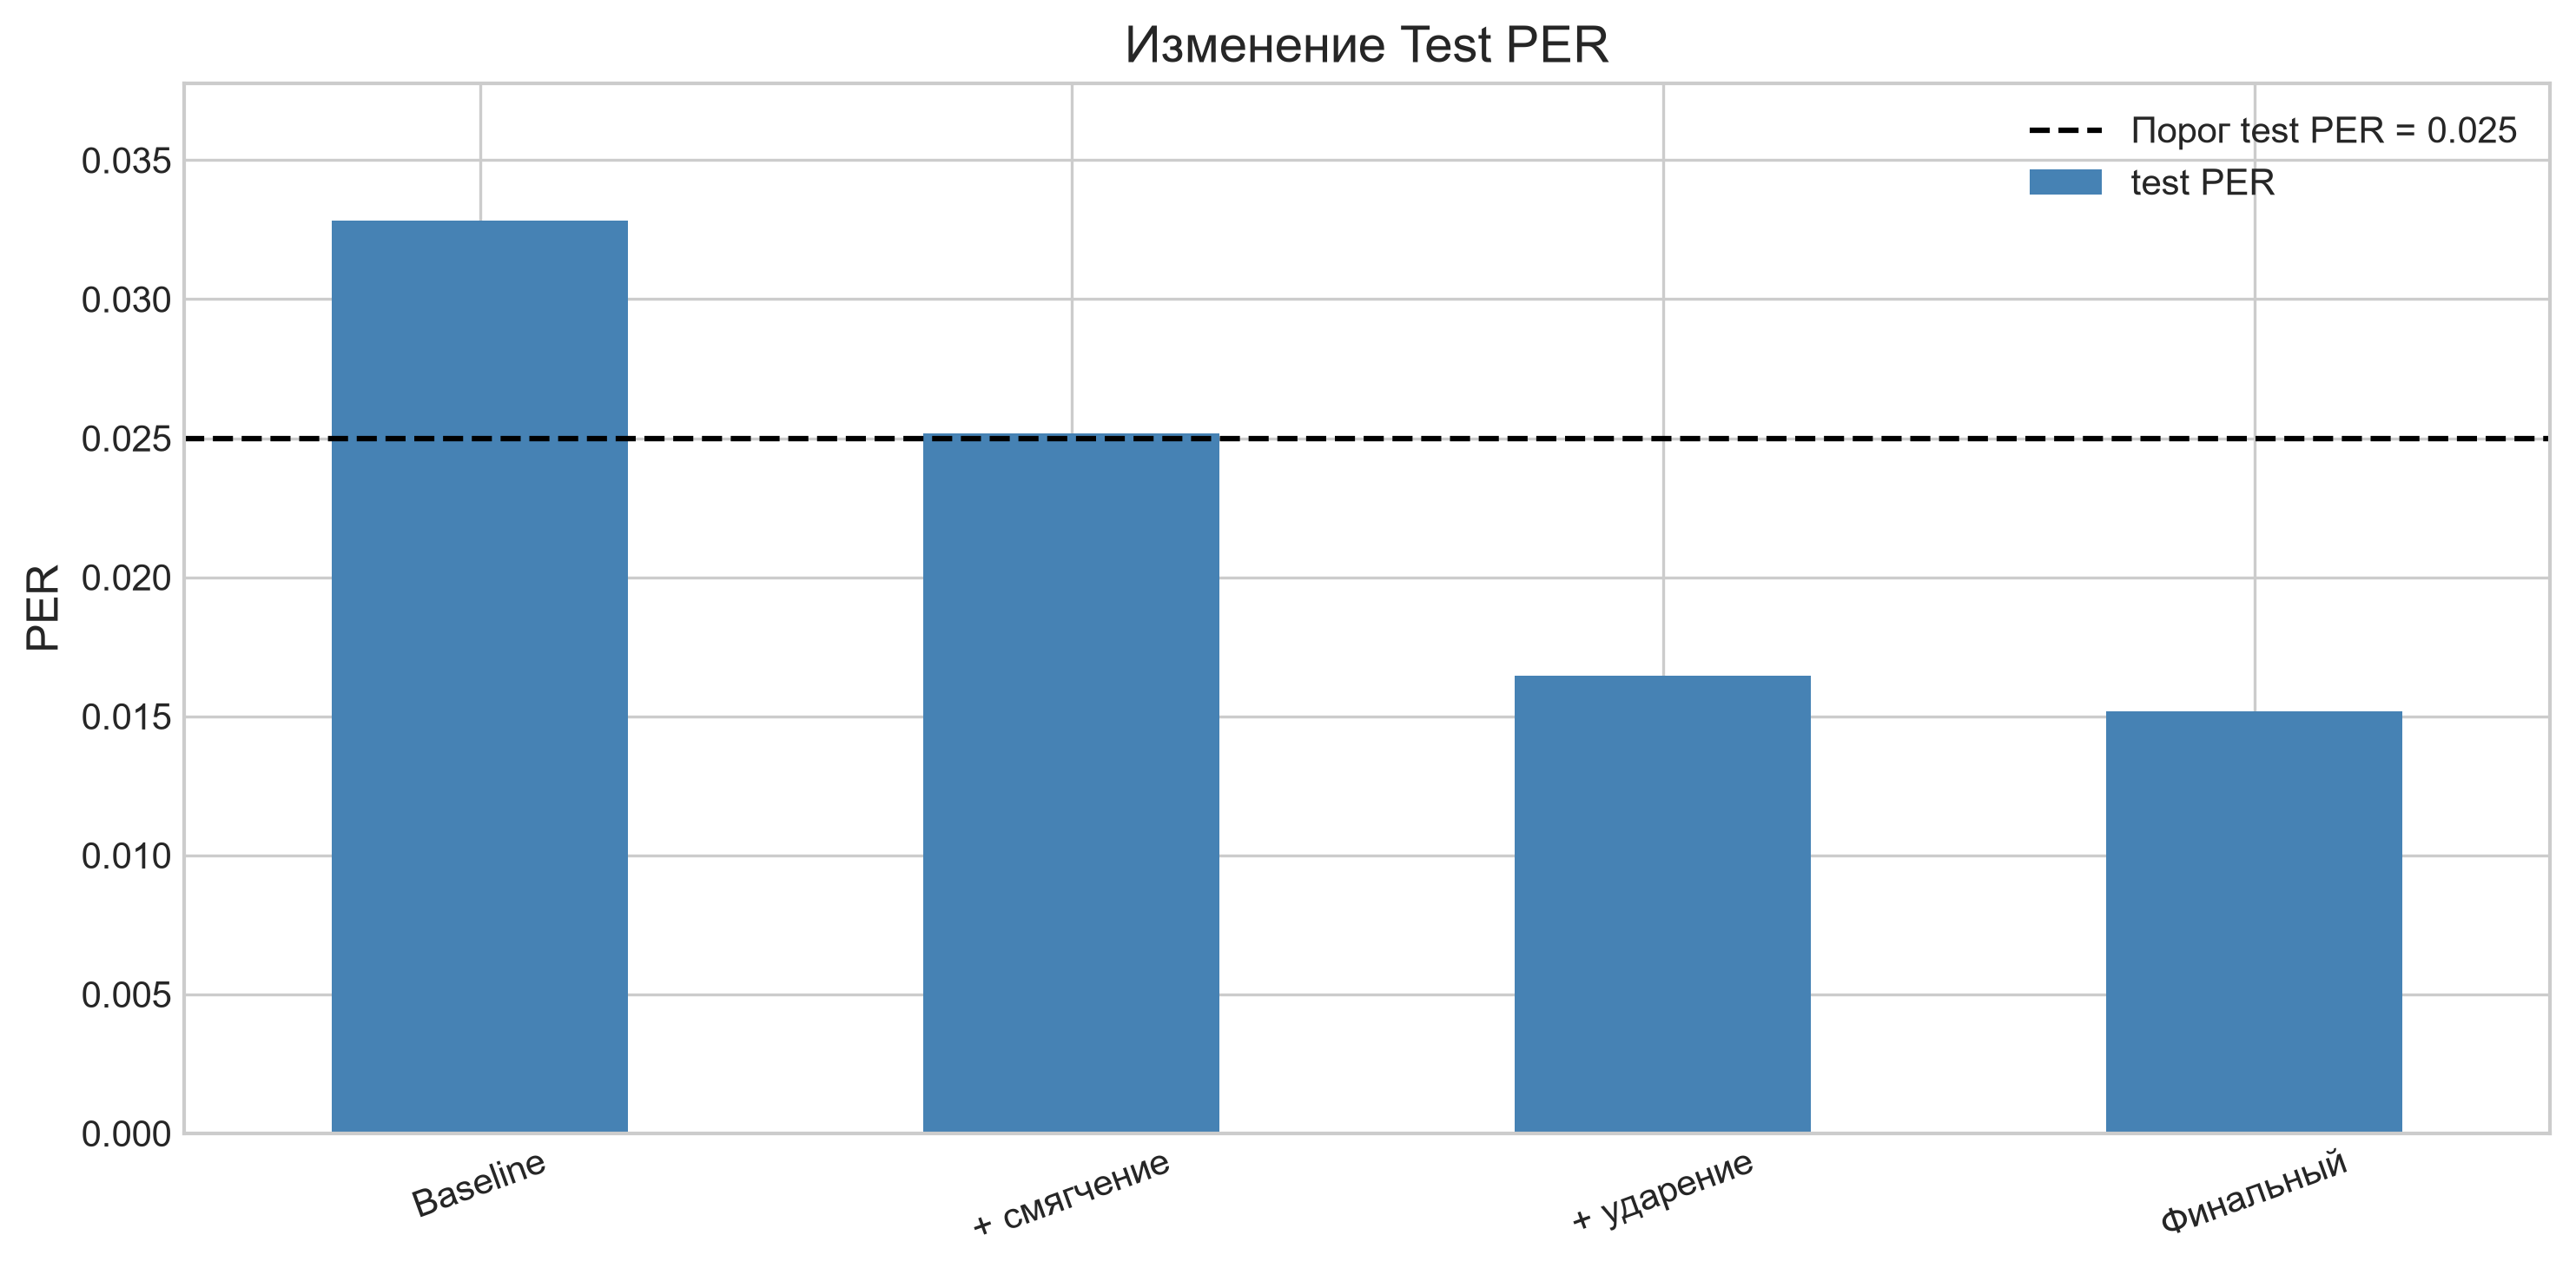

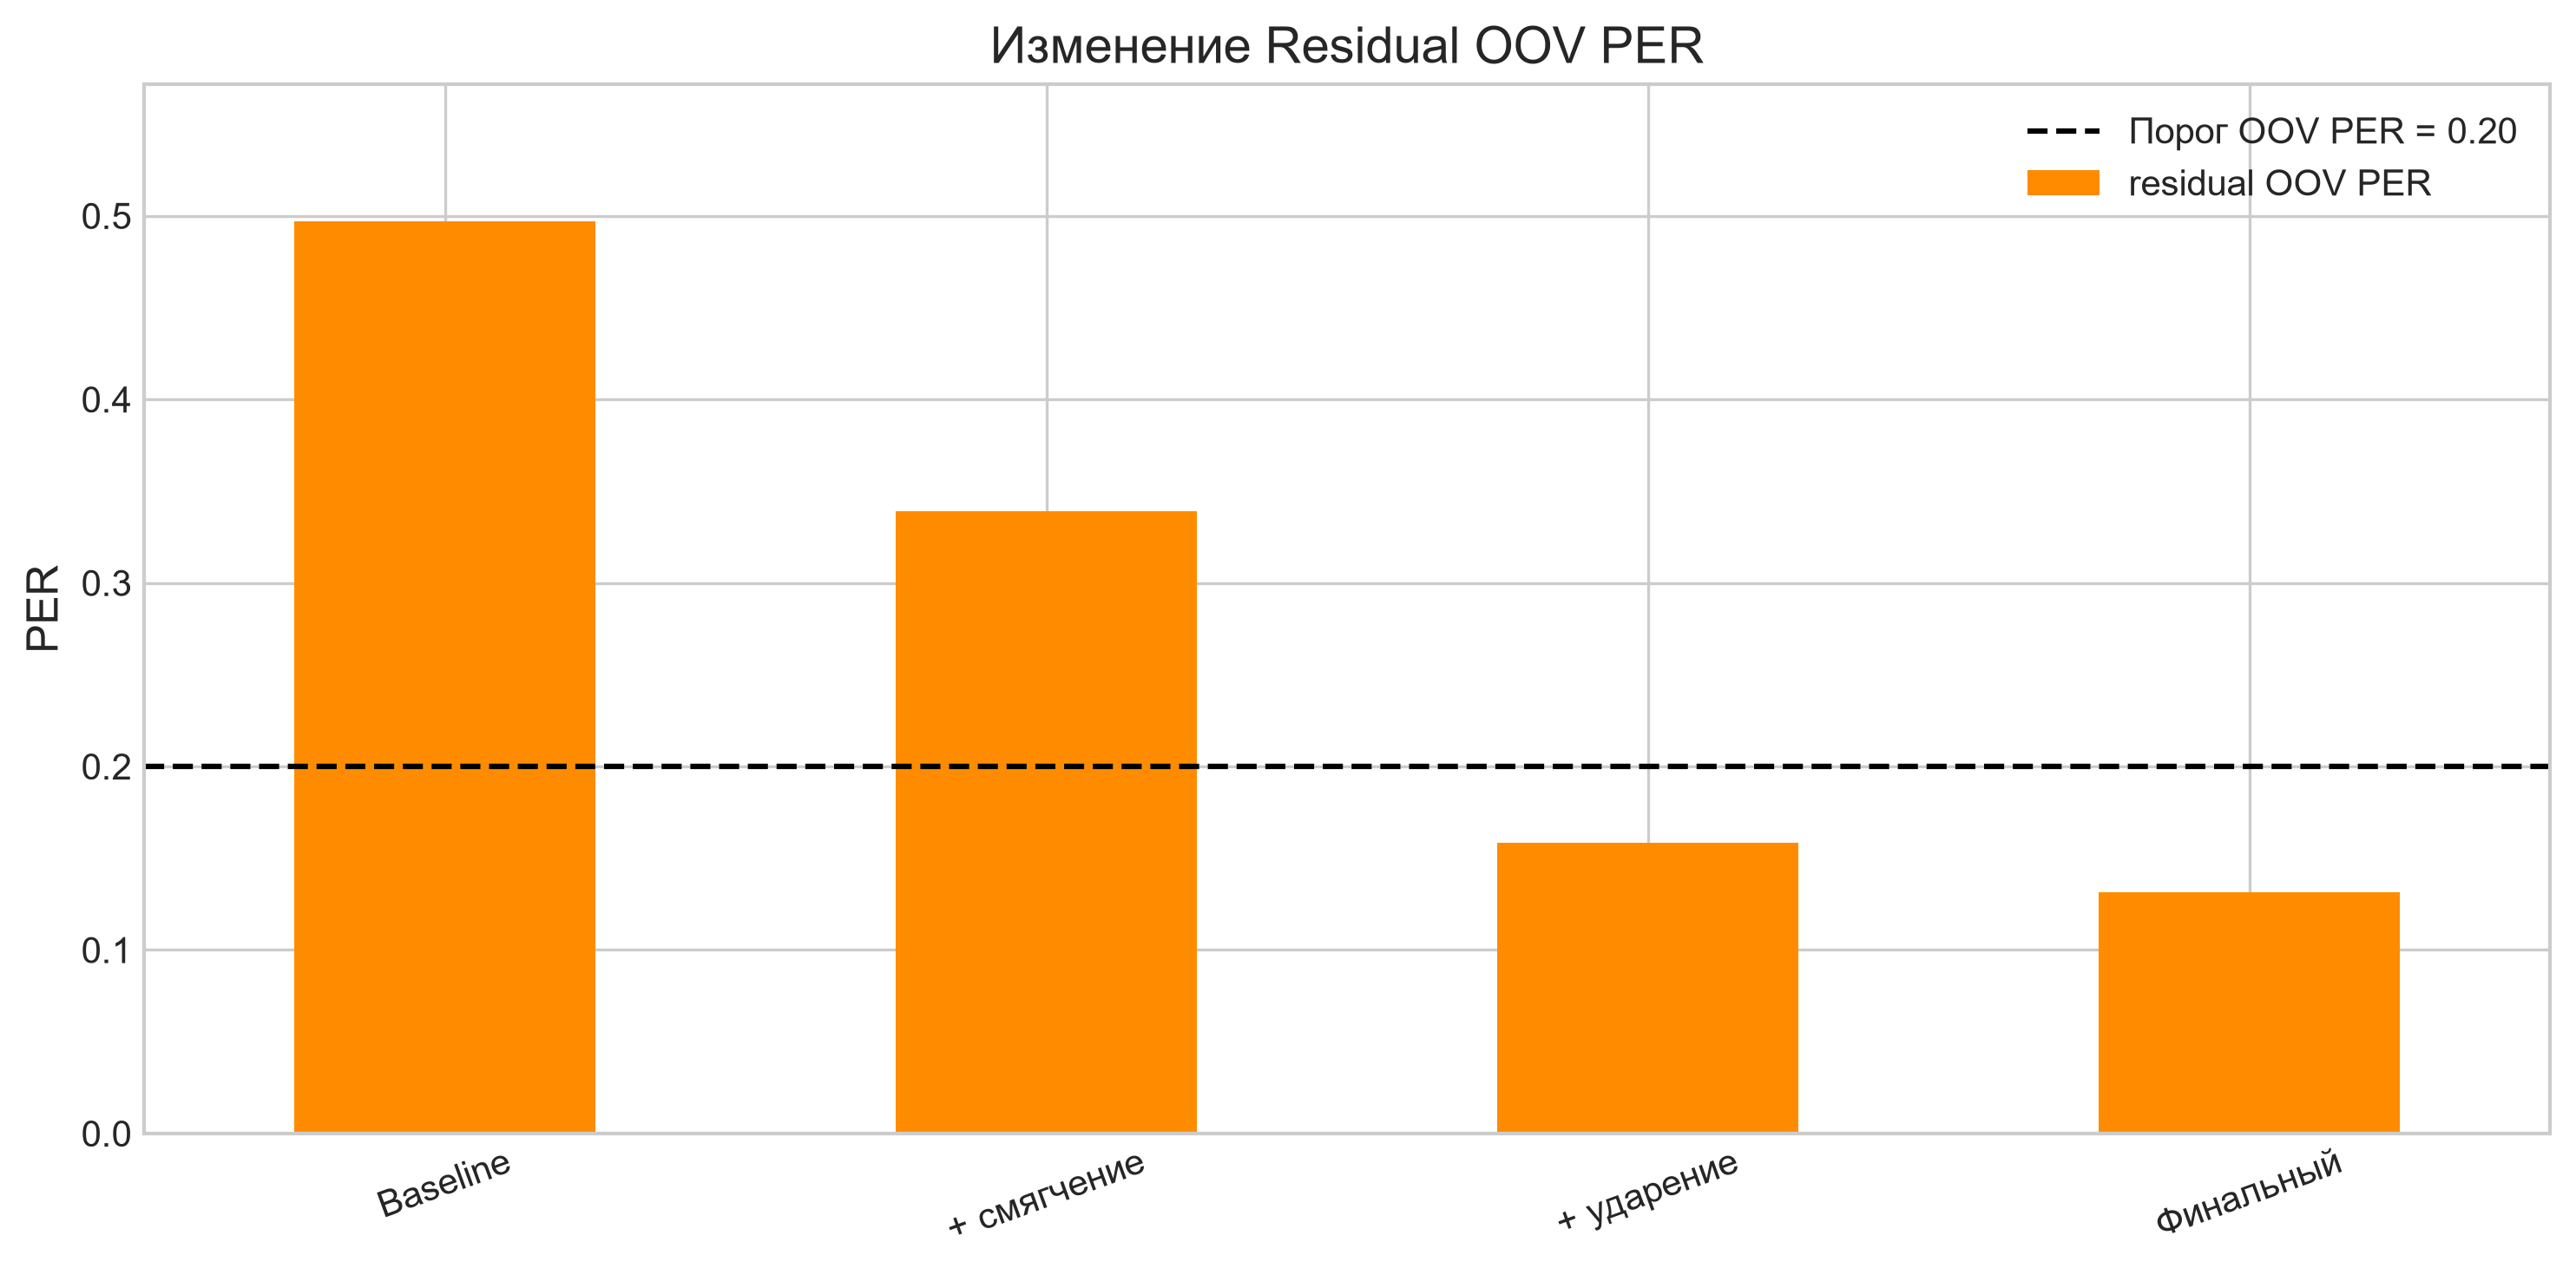

In [ ]:
# Данные для графиков
plot_data = experiments.set_index("Вариант")

# График 1 - Test PER
test_per = plot_data["test PER"]

plt.figure(figsize=(10, 5))

test_per.plot(
    kind="bar",
    color="steelblue",
)

plt.axhline(
    0.025,
    linestyle="--",
    color="black",
    label="Порог test PER = 0.025",
)

plt.ylim(
    0,
    test_per.max() * 1.15,
)

plt.title("Изменение Test PER")
plt.ylabel("PER")
plt.xlabel("")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()


# График 2 - Residual OOV PER
oov_per = plot_data["residual OOV PER"]

plt.figure(figsize=(10, 5))

oov_per.plot(
    kind="bar",
    color="darkorange",
)

plt.axhline(
    0.20,
    linestyle="--",
    color="black",
    label="Порог OOV PER = 0.20",
)

plt.ylim(
    0,
    oov_per.max() * 1.15,
)

plt.title("Изменение Residual OOV PER")
plt.ylabel("PER")
plt.xlabel("")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

### Вывод

Каждый следующий шаг улучшил результат:

- baseline: `test PER = 0.0328`, `OOV PER = 0.4970`
- после смягчения: `test PER = 0.0252`, `OOV PER = 0.3389`
- после добавления оценки ударения: `test PER = 0.0165`, `OOV PER = 0.1584`
- финальный вариант: `test PER = 0.0152`, `OOV PER = 0.1317`

Самое большое улучшение дал этап с оценкой ударения и безударных гласных

По сравнению с baseline итоговый `test PER` уменьшился примерно на **54%**, а `residual OOV PER` - примерно на **74%**

На `train` OOV-модуль не используется, поэтому для всех вариантов `Train PER` остаётся равным **0.0075**

# Часть 10. Финальная модель

In [31]:
final_g2p = G2P(
    corpus_lexicon=corpus_lexicon,
    mfa_lexicon=mfa_lexicon,
    allowed_phones=allowed_phones,
    oov_mode="final",
)

final_train_metrics = calc_metrics(
    final_g2p,
    train,
    title="Final / Train",
)

final_test_metrics = calc_metrics(
    final_g2p,
    test,
    title="Final / Test",
)

Оценка Final / Train: 100%|██████████| 15715/15715 [00:03<00:00, 5055.49it/s]



Final / Train
PER на всём тексте: 0.0075
lexicon.csv: 175243 слов, PER=0.0075
Russian MFA: 0 слов, PER=nan
Остаток OOV: 0 слов, PER=nan, accuracy=nan


Оценка Final / Test: 100%|██████████| 3980/3980 [00:00<00:00, 5579.44it/s]



Final / Test
PER на всём тексте: 0.0152
lexicon.csv: 38588 слов, PER=0.0104
Russian MFA: 4518 слов, PER=0.0035
Остаток OOV: 1251 слов, PER=0.1317, accuracy=0.3197


In [32]:
requirements = pd.DataFrame(
    {
        "Проверка": [
            "PER на всём test",
            "PER остатка OOV",
        ],
        "Получено": [
            final_test_metrics["running_per"],
            final_test_metrics["oov_per"],
        ],
        "Порог": [
            0.025,
            0.20,
        ],
    }
)

requirements["Пройдено"] = (
    requirements["Получено"]
    <= requirements["Порог"]
)

requirements

,Проверка,Получено,Порог,Пройдено
0,PER на всём test,0.015172,0.025,True
1,PER остатка OOV,0.131670,0.200,True


In [33]:
unknown_final = check_inventory(
    final_g2p,
    test,
)

print(
    "Фонемы вне phones_mfa.txt:",
    sorted(unknown_final),
)

Фонемы вне phones_mfa.txt: []


Финальный G2P имеет простой порядок:

1. `lexicon.csv`
2. Russian MFA dictionary
3. собственные правила для остатка OOV

Токен `<SIL>` всегда проходит без изменений

Дополнительно проверяем, что итоговая модель не создаёт фонемы вне `phones_mfa.txt`

# Часть 11. Анализ ошибок

Посмотрим только на настоящий остаток OOV

Для каждого слова посчитаем его собственную ошибку и выведем самые сложные примеры

In [34]:
oov_errors = collect_oov_errors(
    final_g2p,
    test,
)

print(
    "OOV-употреблений:",
    len(oov_errors),
)

print(
    "Полностью правильных:",
    int(oov_errors["correct"].sum()),
)

display(
    oov_errors
    .sort_values(
        ["word_per", "edits"],
        ascending=False,
    )
    .head(30)
)

OOV-употреблений: 1251
Полностью правильных: 400


,id,token,reference,predicted,edits,phones,word_per,correct
546,011915_RUSLAN,буэндиа,b u ɛ n̪ dʲ ɪ a,b ʊ ɪ ɲ dʲ i ə,5,7,0.714286,False
744,015105_RUSLAN,излечиться,ɪ zʲ ʎ ɪ tɕ i t̪ s̪ ə,ɪ z̪ ʎ e tɕ ɪ tʲ sʲ ɪ,6,9,0.666667,False
908,017760_RUSLAN,эдженси,ɛ dʐ ɨ n̪ sʲ ɪ,ɪ d̪ ʐ e n̪ sʲ ɪ,4,6,0.666667,False
1193,021160_RUSLAN,додж,d̪ o tʂ,d̪ o d̪ ʂ,2,3,0.666667,False
155,005605_RUSLAN,заправиться,z̪ ɐ p r a vʲ ɪ t̪ s̪ ə,z̪ ə p r ɐ vʲ i tʲ sʲ ɪ,6,10,0.600000,False
579,012435_RUSLAN,бенуа,bʲ e n̪ ʊ a,bʲ ɪ n̪ u ə,3,5,0.600000,False
792,015770_RUSLAN,анелю,ɐ n̪ ɨ ʎ ʊ,ɐ ɲ ɪ ʎ ʉ,3,5,0.600000,False
1041,019520_RUSLAN,уикли,u ɪ c ʎ ɪ,ʊ i k ʎ ɪ,3,5,0.600000,False
364,009175_RUSLAN,дантеса,d̪ a n̪ t̪ ɛ s̪ ə,d̪ ɐ ɲ tʲ e s̪ ə,4,7,0.571429,False
470,010610_RUSLAN,отживающая,ɐ dʐ ɨ v a j ʉ ɕ ɪ j ə,ɐ d̪ ʐ ɨ v ə j ʊ ɕ a j ɪ,6,11,0.545455,False


In [35]:
error_by_word = (
    oov_errors
    .groupby("token")
    .agg(
        count=("token", "size"),
        mean_per=("word_per", "mean"),
        max_edits=("edits", "max"),
    )
    .sort_values(
        ["mean_per", "count"],
        ascending=False,
    )
)

error_by_word.head(30)

,count,mean_per,max_edits
token,,,
буэндиа,1,0.714286,5
додж,1,0.666667,2
излечиться,1,0.666667,6
эдженси,1,0.666667,4
анелю,1,0.600000,3
бенуа,1,0.600000,3
заправиться,1,0.600000,6
уикли,1,0.600000,3
дантеса,1,0.571429,4


### Вывод по ошибкам

После улучшений полностью правильно транскрибированы **400 из 1 251** OOV-употреблений

Среди самых сложных примеров есть:

- имена и заимствования: `буэндиа`, `эдженси`, `бенуа`
- слова с трудным положением ударения и редукцией гласных
- слова со сложными сочетаниями согласных, например `излечиться` и `заправиться`

Это ожидаемое ограничение простых правил. При этом для задания важнее PER: итоговый `residual OOV PER = 0.1317`, что ниже требуемого порога `0.20`

# Часть 12. Слова с несколькими произношениями и омографы

Ранее мы увидели, что некоторые слова имеют несколько вариантов произношения

Это не всегда настоящие омографы: часть вариантов появляется из-за контекста произношения или особенностей выравнивания

Поэтому здесь используем все слова с несколькими вариантами как **приближённую оценку** проблемы: смотрим, сколько таких слов встречается в `test` и как часто самый частый вариант совпадает с эталоном

In [36]:
multi_words = set(
    multi_pronunciation.index
)

homograph_test = test[
    test["token"].isin(multi_words)
].copy()

homograph_rows = []

for row in homograph_test.itertuples(index=False):
    predicted = final_g2p.transcribe(
        [row.token]
    )[0]

    reference = str(row.phones).split()

    homograph_rows.append(
        {
            "word": row.token,
            "reference": " ".join(reference),
            "predicted": " ".join(predicted),
            "correct": reference == predicted,
        }
    )

homograph_result = pd.DataFrame(
    homograph_rows
)

print(
    "Употреблений слов с несколькими вариантами:",
    len(homograph_result),
)

print(
    "Доля полностью правильных:",
    homograph_result["correct"].mean(),
)

display(
    homograph_result[
        ~homograph_result["correct"]
    ].head(20)
)

Употреблений слов с несколькими вариантами: 7169
Доля полностью правильных: 0.7903473287766773


,word,reference,predicted,correct
1,в,f,v,False
2,моей,m ɐ j i,m ɐ j e j,False
8,не,ɲ e,ɲ i,False
16,дела,dʲ e ɫ ə,dʲ ɪ ɫ a,False
20,на,n̪ a,n̪ ə,False
28,статью,s̪ t̪ ɐ tʲ j u,s̪ t̪ a tʲ j ʊ,False
29,об,ɐ p,ɐ b,False
38,об,ɐ p,ɐ b,False
39,в,f,v,False
43,не,ɲ e,ɲ i,False


### Вывод

В `test` получилось **7 169 употреблений** слов, для которых в `lexicon.csv` есть несколько вариантов произношения

Самый частый словарный вариант полностью совпал с эталоном примерно в **79.0%** случаев

Эту цифру нельзя считать точной оценкой только омографов: сюда входят и обычные контекстные варианты произношения. Но результат показывает ограничение словарного подхода - без контекста один и тот же написанный токен всегда получает один и тот же выбранный вариант

Для более точной работы с настоящими омографами потребовалось бы учитывать соседние слова. В этой лабораторной это не выполняю, т.к. требования по PER уже выполнил

# Итог

В лабораторной работе были подготовлены фонетические данные корпуса RUSLAN и реализован G2P-модуль

После фильтрации осталось **19 695 предложений**. В корпусе найдено **55 речевых фонем**, и все они входят в заданный набор `phones_mfa.txt`

Сначала был собран baseline

`lexicon.csv -> Russian MFA -> простой перевод букв`.

Его результаты на `test`:

- `test PER = 0.0328`
- `residual OOV PER = 0.4970`.

Главной проблемой оказался остаток OOV - слова, которых нет ни в одном словаре. Для них были добавлены простые правила:

- смягчение согласных
- обработка `е/ё/ю/я`
- оценка ударения по данным `train`
- изменение безударных гласных
- оглушение и озвончение некоторых согласных
- несколько правил для сочетаний букв

После улучшений получено:

- `test PER = 0.0152` при требовании `<= 0.025`
- `residual OOV PER = 0.1317` при требовании `<= 0.20`

Оба требования выполнены. Все фонемы, которые выдаёт финальная модель, входят в `phones_mfa.txt`